In [2]:
import numpy as np
import matplotlib.pyplot as plt

In [29]:
# AI disclaimer: generated with Claude Opus 5.5 (claude-opus-5-5)
# Subaperture layout from van Dam, "Centroid, Subaperture and Actuator Conventions",
# Keck Adaptive Optics Note #368 (2005), Table 2 and Section 1.3.

def keck_subap_mask():
    """Boolean (20, 20) mask of the 304 illuminated Keck WFS subapertures (KAON 368, Table 2).

    Row 0 is the bottom of the pupil, so plot with origin='lower'.
    """
    n = 20
    # row widths from bottom to top, including the obscured cells in the middle rows
    widths = (6, 10, 14, 16, 16, 18, 18, 20, 20, 20, 20, 20, 20, 18, 18, 16, 16, 14, 10, 6)
    # central obscuration: width of the centered gap in each affected row
    gaps = {8: 2, 9: 4, 10: 4, 11: 2}

    mask = np.zeros((n, n), dtype=bool)
    for row, w in enumerate(widths):
        start = (n - w) // 2
        mask[row, start:start + w] = True
        g = gaps.get(row, 0)
        if g:
            gstart = (n - g) // 2
            mask[row, gstart:gstart + g] = False
    return mask


def subaps_to_grid(data, mask, fill=np.nan):
    """Scatter (..., 304) subaperture data onto a (..., 20, 20) grid.

    Leading axes (e.g. time) are preserved.
    """
    grid = np.full(data.shape[:-1] + mask.shape, fill, dtype=np.result_type(data, fill))
    grid[..., mask] = data
    return grid


def centroids_to_grids(slopes, mask, fill=np.nan):
    """Split (..., 608) centroids ordered [c0x, c0y, c1x, c1y, ...] (KAON 368, Section 1.3)
    into x and y grids of shape (..., 20, 20).
    """
    return subaps_to_grid(slopes[..., 0::2], mask, fill), subaps_to_grid(slopes[..., 1::2], mask, fill)


mask_grid = keck_subap_mask()

In [30]:
fpath = '/Users/kderby/data/2026-11-01/IMAG/i261101_a017002.fits/'

wfs_file = 'LGS-ocam2k.npz'
wfs_data = np.load(fpath + wfs_file)
slopes_orig = wfs_data['SHWFS1Centroid'].astype(np.float64)
subaps_orig = wfs_data['SHWFS1SubAper'].astype(np.float64)
times = wfs_data['timestamp']

dm_file = 'LGS-xinetics.npz'
dm_data = np.load(fpath + dm_file)
residuals_orig = dm_data['residualWaveFront'].astype(np.float64)

recon_file = '1Nov0045.mr'
recon_orig = np.fromfile(fpath + recon_file, dtype='>f4').astype(np.float64)

cog_file = 'lgs3304_1.cog'
cog_orig = np.fromfile(fpath + cog_file, dtype='>f4').astype(np.float64)

In [31]:
print(f'Slopes Shape: ' + str(slopes_orig.shape))
print(f'Subaps Shape: ' + str(subaps_orig.shape))
print(f'Times shape: ' + str(times.shape))
print(f'Residuals Shape: ' + str(residuals_orig.shape))
print(f'Recon Shape: ' + str(recon_orig.shape))
print(f'cog Shape: ' + str(cog_orig.shape))

Slopes Shape: (89990, 608)
Subaps Shape: (89990, 304)
Times shape: (89990,)
Residuals Shape: (89990, 349)
Recon Shape: (214016,)
cog Shape: (608,)


Text(0, 0.5, 'Residual Error')

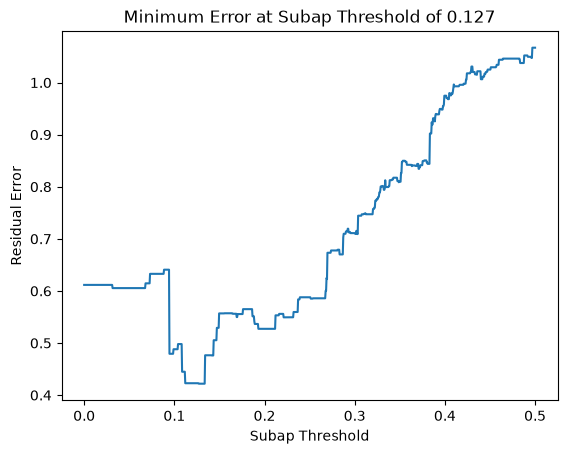

In [20]:
errs = np.zeros(1000)
threshs = np.linspace(0, 0.5, 1000)
for i, thresh in enumerate(threshs):
    mask_subap = subaps_orig[0, :] > (thresh * subaps_orig.max())
    mask_subap = np.repeat(mask_subap, repeats=2)
    recon = recon_orig.reshape(352, 608)[:-3, mask_subap]
    residual = residuals_orig[0, :]
    slope = slopes_orig[0, mask_subap]
    check = (recon @ slope)
    errs[i] = np.sqrt(np.mean((residual - check) ** 2))

plt.plot(threshs, errs)
plt.title(f'Minimum Error at Subap Threshold of {threshs[np.argmin(errs)]:.3f}')
plt.xlabel('Subap Threshold')
plt.ylabel('Residual Error')

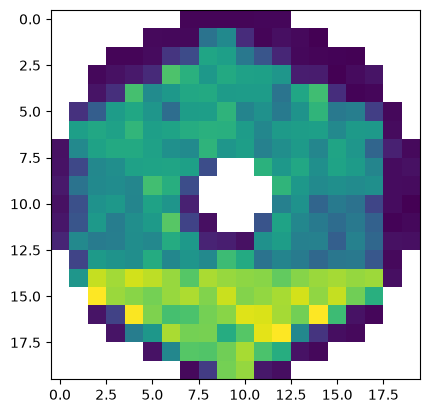

In [ ]:
img_subap = subaps_to_grid(subaps_orig[0], mask_grid)

plt.figure()
plt.imshow(img_subap)

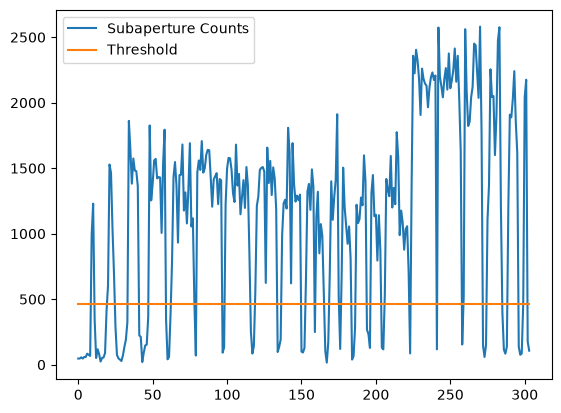

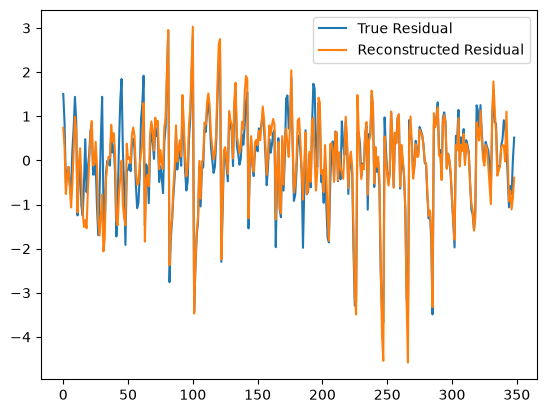

In [21]:
# subap mask
# only use subaps with subaps > threshold * subaps_max
thresh_subaps = 0.127
mask_subap = subaps_orig[0, :] > (thresh_subaps * subaps_orig.max())
mask_subap = np.repeat(mask_subap, repeats=2)

plt.figure()
plt.plot(subaps_orig[0, :], label='Subaperture Counts')
plt.plot(np.ones_like(subaps_orig[0, :]) * thresh_subaps * subaps_orig.max(), label='Threshold')
plt.legend()

# reshape reconstructor
# throw out last three rows of TTF, only select valid subaps
recon = recon_orig.reshape(352, 608)[:-3, mask_subap]

# sanity check 
# reconstructor with slopes should give dm residuals
residual = residuals_orig[0, :]
slope = slopes_orig[0, mask_subap]
check = (recon @ slope)

plt.figure()
plt.plot(residual, label='True Residual')
plt.plot(check, label='Reconstructed Residual')
plt.legend()

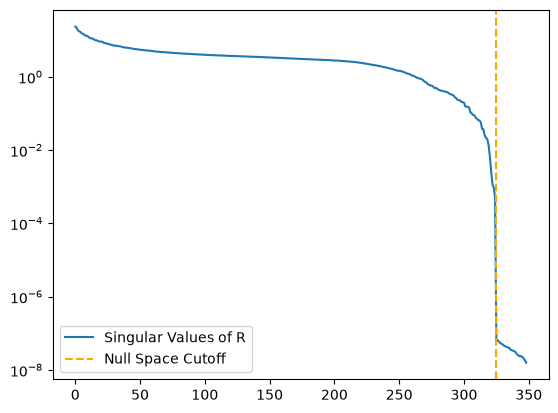

In [38]:
# R is the reconstructor
R = recon

# c are the reference centroids (cog)
# make sure to select only valid subapertures
c = cog_orig[mask_subap]

# s are slope measurements of the source relative to c
# again only select valid subapertures
s = slopes_orig[0, mask_subap]

# r are absolute slope measurements
r = s + c

# SVD of R
U, S, Vt = np.linalg.svd(R)

# we want Z: an orthonormal basis for the null space of R
# for now, use a threshold of 1e-5 to select "zero-valued" singular values
thresh_S = 1e-5
rank = np.sum(S > thresh_S)

plt.figure()
plt.semilogy(S, label='Singular Values of R')
plt.axvline(rank, label='Null Space Cutoff', color='orange', linestyle='dashed')
plt.legend()

# use those to select the columns corresponding to the null space of R
Z = Vt[rank:, :].squeeze()

In [39]:
# part of c in the null space of R
c_null = Z.T @ (Z @ c)

# part of s in the null space of R
s_null = Z.T @ (Z @ s)

# slope discrepancy metric 
g0 = (s_null.T @ c_null) / (c_null.T @ c_null)

# slope discrepancy across entire timeseries
s_all = slopes_orig[:, mask_subap]
g_all = (s_all @ c_null) / (c_null @ c_null)

# average slope discrepancy 
g = np.mean(g_all)

print(g)
print(g_all[0])
print(g0)

-0.8490235466769706
-0.8892557245676526
-0.8892557245676526


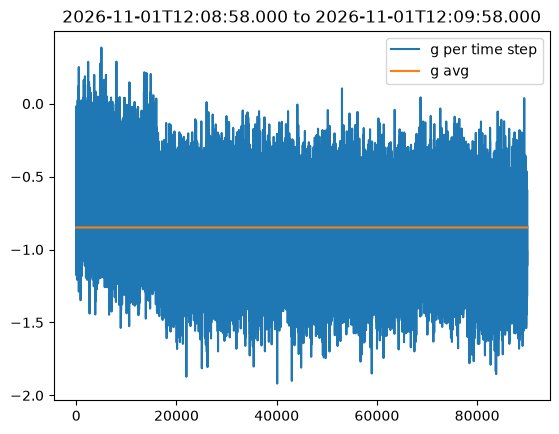

In [40]:
plt.figure()
plt.plot(g_all, label='g per time step')
plt.plot(np.ones_like(g_all) * g, label='g avg')
plt.title(times[0] + ' to ' + times[-1])
plt.legend()

/var/folders/r6/26_t2lnn2x71rdq1x7m9r8lr0000gp/T/ipykernel_29993/739450026.py:10: RuntimeWarning: invalid value encountered in divide
  g_all = (s_all @ c_null) / (c_null @ c_null)


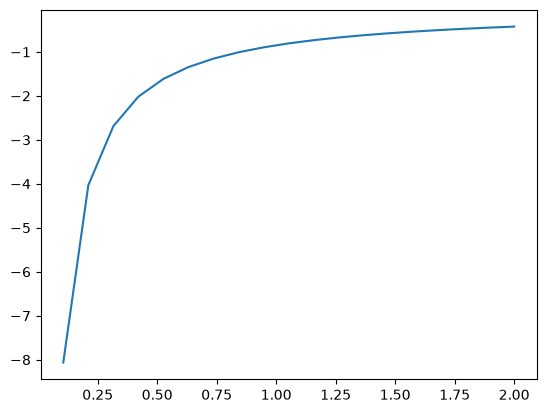

In [36]:
cgain_bench = 0.528

alphas = np.linspace(0, 2, 20)
gs = np.zeros_like(alphas)

for i, alpha in enumerate(alphas):
    c = cog_orig[mask_subap] * alpha 
    c_null = Z.T @ (Z @ c)
    s_all = slopes_orig[:, mask_subap]
    g_all = (s_all @ c_null) / (c_null @ c_null)
    gs[i] = np.mean(g_all)

plt.plot(alphas, gs)